In [1]:
import numpy as np
import pandas as pd 
from sklearn.preprocessing import QuantileTransformer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score
from sklearn.compose import ColumnTransformer
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

In [2]:
np.random.seed(42)

n = 500

age = np.random.normal(35, 10, n).clip(18, 70)
monthly_spend = np.random.lognormal(7, 0.8, n)
visits = np.random.poisson(5, n)

# Create subscription probability
log_odds = (
    -3
    + 0.04 * age
    + 0.0008 * monthly_spend
    + 0.12 * visits
)

probability = 1 / (1 + np.exp(-log_odds))
subscribed = np.random.binomial(1, probability)

df = pd.DataFrame({
    "Age": age,
    "MonthlySpend": monthly_spend,
    "VisitsPerMonth": visits,
    "Subscribed": subscribed
})

In [3]:
df.head()

,Age,MonthlySpend,VisitsPerMonth,Subscribed
0,39.967142,2300.638652,4,1
1,33.617357,5051.968824,7,1
2,41.476885,358.219505,7,0
3,50.230299,1720.508885,2,1
4,32.658466,651.635883,5,0


In [4]:
df .isnull().sum()

Age               0
MonthlySpend      0
VisitsPerMonth    0
Subscribed        0
dtype: int64

In [5]:
df.describe()

,Age,MonthlySpend,VisitsPerMonth,Subscribed
count,500.000000,500.000000,500.000000,500.000000
mean,35.182935,1529.194396,4.992000,0.502000
std,9.523649,1365.801182,2.294005,0.500497
min,18.000000,126.784740,0.000000,0.000000
25%,27.996926,681.144626,3.000000,0.000000
50%,35.127971,1121.951989,5.000000,1.000000
75%,41.367833,1846.403329,6.000000,1.000000
max,70.000000,9008.336018,12.000000,1.000000


In [6]:
df.shape

(500, 4)

In [7]:
df.iloc[:,0:3]

,Age,MonthlySpend,VisitsPerMonth
0,39.967142,2300.638652,4
1,33.617357,5051.968824,7
2,41.476885,358.219505,7
3,50.230299,1720.508885,2
4,32.658466,651.635883,5
...,...,...,...
495,40.389100,875.784246,5
496,24.627538,4619.996477,6
497,33.096613,1831.103902,5
498,26.243817,694.406003,4


In [8]:
x=df.iloc[:,0:3]
# y=df.drop(columns=["Age","MonthlySpend","VisitsPerMonth"])Logistic regression expects 1d array not 2D
y=df["Subscribed"]

In [9]:
x_train,x_test,y_train,y_test=train_test_split(
    x,
    y,
    random_state=0,
    test_size=0.2
)

In [10]:
lr=LogisticRegression()
lr.fit(x_train,y_train)
y_pred=lr.predict(x_test)
accuracy_score(y_test,y_pred)

0.64

In [11]:
lr=LogisticRegression()
np.mean(cross_val_score(lr,x,y,scoring="accuracy"))

np.float64(0.648)

### Without quantile transformer we get this accuracy

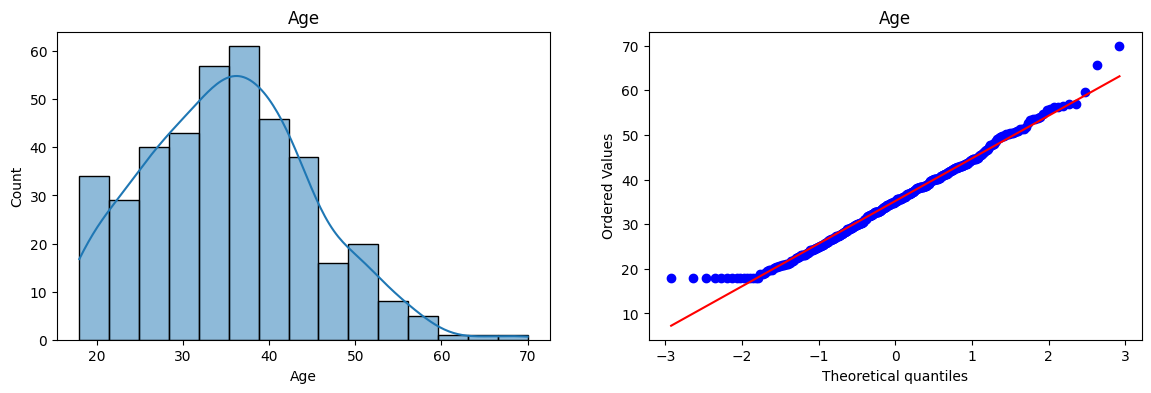

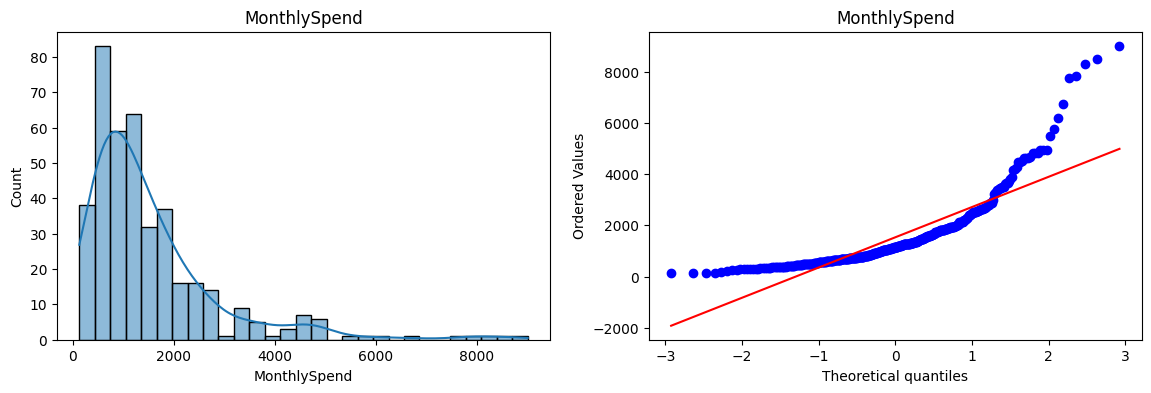

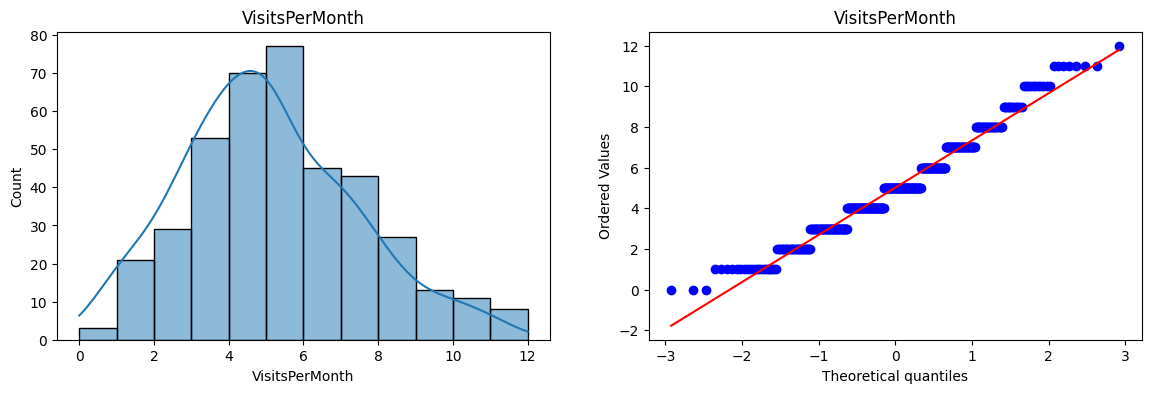

In [12]:
for col in x_train.columns:
    plt.figure(figsize=(14,4))
    plt.subplot(121)
    sns.histplot(x_train[col],kde=True)
    plt.title(col)

    plt.subplot(122)
    stats.probplot(x_train[col],dist="norm",plot=plt)
    plt.title(col)

In [13]:
qt=QuantileTransformer(n_quantiles=400,output_distribution="normal",random_state=0)
x_train_transformed=qt.fit_transform(x_train)
x_test_transformed=qt.transform(x_test)
lr=LogisticRegression()
lr.fit(x_train_transformed,y_train)
y_pred2=lr.predict(x_test_transformed)
accuracy_score(y_test,y_pred2)

0.66

In [14]:
qt=QuantileTransformer(n_quantiles=400,output_distribution="normal",random_state=42)
x_trans=qt.fit_transform(x)
lr=LogisticRegression()
np.mean(cross_val_score(lr,x_trans,y,scoring="accuracy"))

np.float64(0.674)

### As we can see the accuracy with quantile transformer and we get a better accuracy

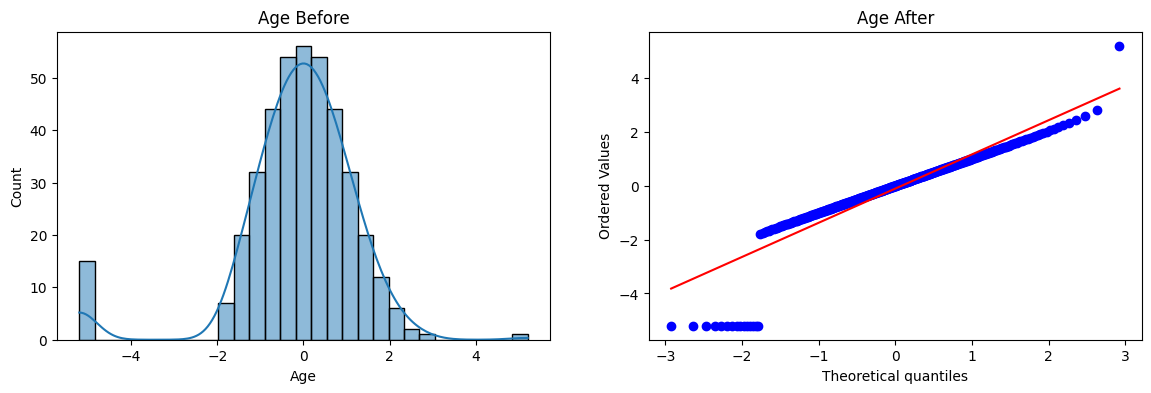

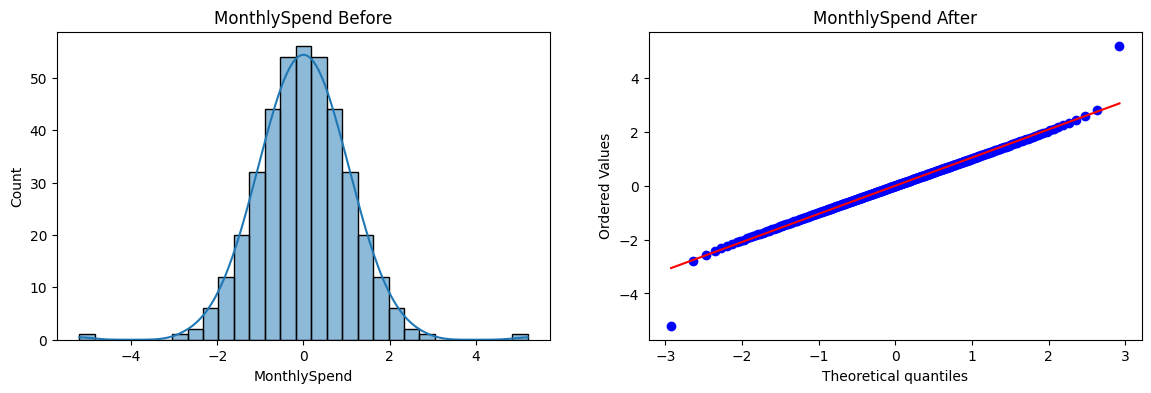

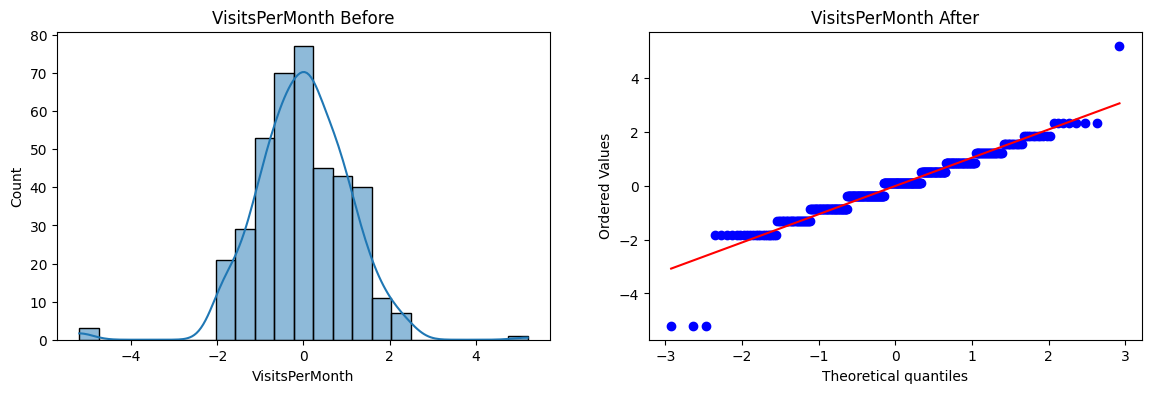

In [21]:
x_train_trans_df=pd.DataFrame(x_train_transformed,columns=x_train.columns)
for col in x_train.columns:
    plt.figure(figsize=(14,4))
    plt.subplot(121)
    sns.histplot(x_train_trans_df[col],kde=True)
    plt.title(f"{col} Before")

    plt.subplot(122)
    stats.probplot(x_train_trans_df[col],dist="norm",plot=plt)
    plt.title(f"{col} After")

In [16]:
qt=ColumnTransformer([("trans",QuantileTransformer(output_distribution="normal",n_quantiles=400,random_state=42),
                      ["MonthlySpend","VisitsPerMonth"])],
                    remainder="passthrough")

In [17]:
x_train_transformed2=qt.fit_transform(x_train)
x_test_transformed2=qt.transform(x_test)
lr=LogisticRegression()
lr.fit(x_train_transformed2,y_train)
y_pred3=lr.predict(x_test_transformed2)
accuracy_score(y_test,y_pred3)

0.67

### We can see that with selecting only necessary column for transformer we get a little better accuracy

In [18]:
qt=ColumnTransformer([("trans",QuantileTransformer(output_distribution="normal",
                    n_quantiles=400,random_state=42),
                    ["MonthlySpend","VisitsPerMonth"])],
                    remainder="passthrough")
x_trans1=qt.fit_transform(x)
lr=LogisticRegression()
np.mean(cross_val_score(lr,x_trans1,y,scoring="accuracy"))

np.float64(0.674)

### But though there not ,uch change accuracy in cross val score